# Enkelvoudige en meervoudige regressie
Eerst weer data inlezen bij Yahoo Finance en bij de FED in St. Louis:<br>
https://finance.yahoo.com/ <br>
https://fred.stlouisfed.org/categories

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from sklearn.linear_model import LinearRegression
from datetime import date

#Clear output
from google.colab import output
output.clear()

# Data inlezen
Alle libraries geinstalleerd, nu de begin- en einddatum:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

De grondstoffen en indicatoren:

In [ ]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Portfolio-data inlezen:

In [ ]:
apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Portfolio-tabel van tabelnamen voorzien, alleen de slotkoersen selecteren en schonen:

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

Price,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Ticker,AAPL_Apple,SHEL_Shell,NOC_Northrop,TSM_TSMC,RIO_RioTinto,GE_GE,GS_GoldmanSachs,BOND_Bond,BTC-USD_Bitcoin,XRP-USD_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63755.320312,0.526112
2024-04-27,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63419.140625,0.517775


In de kolomnamen staat nu zowel de Price als de Ticker.<br>
Dit gaat problemen opleveren als je naar een kolomnaam wilt verwijzen. We gaan de kolomnamen dus aanpassen (door er in plaats van een MultiIndex een SingleIndex naam van te maken):

In [ ]:
#nans_gevuld.columns = nans_gevuld.columns.get_level_values(1).str.replace(r'(?<=_).*', '', regex=True)
nans_gevuld.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]

In [ ]:
nans_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63755.320312,0.526112
2024-04-27,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63419.140625,0.517775
2024-04-28,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63113.230469,0.510377


Portfolio's maken van de grondstoffen en de indicatoren:

In [ ]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]

grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen, hout, katoen, rubber, wol, zonnebloem, uranium], axis=1)
grondstoffen_1.columns = ["Close_Graan", "Close_Koffie", "Close_Vlees", "Close_Gas", "Close_Kolen", "Close_Hout", "Close_Katoen", "Close_Rubber", "Close_Wol", "Close_Zonnebloem", "Close_Uranium"]

grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Close_Olie", "Close_Goud", "Close_Palladium"]
#grondstoffen_2.columns = grondstoffen_2.columns.get_level_values(1).str.replace(r'(?<=_).*', '', regex=True)

Ook hier passen we de kolomnamen van de portfolio's aan.

Portfolio's forward fillen:

In [ ]:
indicatoren = indicatoren.ffill()
grondstoffen_1 = grondstoffen_1.ffill()
grondstoffen_2 = grondstoffen_2.ffill()

Maak 1 grondstoffenportfolio:

In [ ]:
grondstoffen_compleet = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_compleet = grondstoffen_compleet.ffill()
grondstoffen_compleet

,Close_Graan,Close_Koffie,Close_Vlees,Close_Gas,Close_Kolen,Close_Hout,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,298.811,90.602273,107.788108,925.980943,1171.085417,71.638853,81.930000,2291.399902,951.900024


En nu het 'piece-de-resistance': 3 portfolio's (portfolio, grondstoffen en indicatoren) samenvoegen:

In [ ]:
apt = pd.concat([nans_gevuld, grondstoffen_compleet, indicatoren], axis=1)
apt_fill = apt.ffill()
apt_fill = apt_fill.dropna()
apt_fill

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium,Rente,Inflatie
2018-05-07,46.290001,69.730003,317.130005,38.450001,55.480000,67.429596,237.199997,102.720001,9373.009766,0.832641,...,94.478571,76.123690,1648.876010,938.999457,21.978261,70.730003,1312.199951,964.299988,1.70,2.17
2018-05-08,46.512501,70.029999,329.269989,39.180000,55.410000,68.388084,237.000000,102.589996,9234.820312,0.813970,...,94.478571,76.123690,1648.876010,938.999457,21.978261,69.059998,1312.000000,965.599976,1.70,2.16
2018-05-09,46.840000,71.709999,327.589996,39.349998,56.560001,70.065437,241.729996,102.440002,9325.179688,0.802043,...,94.478571,76.123690,1648.876010,938.999457,21.978261,71.139999,1311.300049,972.799988,1.70,2.18
2018-05-10,47.509998,71.029999,326.410004,39.770000,57.349998,70.400902,243.440002,102.559998,9043.940430,0.758237,...,94.478571,76.123690,1648.876010,938.999457,21.978261,71.360001,1320.800049,996.099976,1.70,2.17
2018-05-11,47.147499,71.989998,325.299988,39.910000,57.389999,69.969589,242.919998,102.690002,8441.490234,0.684948,...,94.478571,76.123690,1648.876010,938.999457,21.978261,70.699997,1319.000000,987.400024,1.70,2.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63419.140625,0.517775,...,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024,5.33,2.43
2024-04-28,169.300003,73.269997,480.450012,138.300003,68.239998,162.350006,427.570007,89.120003,63113.230469,0.510377,...,90.602273,107.788108,925.980943,1171.085417,71.638853,83.849998,2334.800049,957.400024,5.33,2.43
2024-04-29,173.500000,73.120003,486.220001,138.500000,69.010002,164.490005,430.809998,89.470001,63841.121094,0.515432,...,90.602273,107.788108,925.980943,1171.085417,71.638853,82.629997,2345.399902,976.700012,5.33,2.41
2024-04-30,170.330002,71.660004,485.029999,137.339996,67.830002,161.820007,426.709991,89.180000,60636.855469,0.500065,...,90.602273,107.788108,925.980943,1171.085417,71.638853,81.930000,2291.399902,951.900024,5.33,2.41


Alles omzetten naar prijsveranderingen als je het dagrendement wilt berekenen:

In [ ]:
#return_portfolio = np.log(apt_fill / apt_fill.shift(1))
return_portfolio = apt_fill.pct_change()
return_portfolio.head(10)

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium,Rente,Inflatie
2018-05-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-08,0.004807,0.004302,0.038281,0.018986,-0.001262,0.014215,-0.000843,-0.001266,-0.014743,-0.022424,...,0.0,0.0,0.0,0.0,0.0,-0.023611,-0.000152,0.001348,0.0,-0.004608
2018-05-09,0.007041,0.023990,-0.005102,0.004339,0.020754,0.024527,0.019958,-0.001462,0.009785,-0.014653,...,0.0,0.0,0.0,0.0,0.0,0.030119,-0.000533,0.007457,0.0,0.009259
2018-05-10,0.014304,-0.009483,-0.003602,0.010673,0.013967,0.004788,0.007074,0.001171,-0.030159,-0.054618,...,0.0,0.0,0.0,0.0,0.0,0.003093,0.007245,0.023951,0.0,-0.004587
2018-05-11,-0.007630,0.013515,-0.003401,0.003520,0.000697,-0.006127,-0.002136,0.001268,-0.066614,-0.096657,...,0.0,0.0,0.0,0.0,0.0,-0.009249,-0.001363,-0.008734,0.0,-0.009217
2018-05-12,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.007510,0.017209,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
2018-05-13,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.025756,0.070347,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
2018-05-14,-0.002333,0.002084,-0.020227,0.001002,0.008015,0.007534,0.004075,-0.000390,-0.000820,-0.006503,...,0.0,0.0,0.0,0.0,0.0,0.003678,-0.001895,0.010634,0.0,0.000000
2018-05-15,-0.009088,0.007070,0.003922,-0.016270,-0.005704,0.000000,-0.009635,-0.003799,-0.023680,-0.057106,...,0.0,0.0,0.0,0.0,0.0,0.004932,-0.020965,-0.012526,0.0,0.013953
2018-05-16,0.009333,-0.003166,0.003719,0.012468,0.024513,0.021754,-0.002484,-0.001467,-0.016633,0.022178,...,0.0,0.0,0.0,0.0,0.0,0.002524,0.001009,-0.000710,0.0,-0.004587


We zijn nu bijna waar we wezen willen: alle rijen en kolommen gevuld. Laatste schoonmaakactie: het verwijderen / filteren van de eerste rij met NaN's<p>


In [ ]:
return_portfolio_final = return_portfolio.dropna()
return_portfolio_final

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium,Rente,Inflatie
2018-05-08,0.004807,0.004302,0.038281,0.018986,-0.001262,0.014215,-0.000843,-0.001266,-0.014743,-0.022424,...,0.00000,0.000000,0.000000,0.000000,0.000000,-0.023611,-0.000152,0.001348,0.0,-0.004608
2018-05-09,0.007041,0.023990,-0.005102,0.004339,0.020754,0.024527,0.019958,-0.001462,0.009785,-0.014653,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.030119,-0.000533,0.007457,0.0,0.009259
2018-05-10,0.014304,-0.009483,-0.003602,0.010673,0.013967,0.004788,0.007074,0.001171,-0.030159,-0.054618,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.003093,0.007245,0.023951,0.0,-0.004587
2018-05-11,-0.007630,0.013515,-0.003401,0.003520,0.000697,-0.006127,-0.002136,0.001268,-0.066614,-0.096657,...,0.00000,0.000000,0.000000,0.000000,0.000000,-0.009249,-0.001363,-0.008734,0.0,-0.009217
2018-05-12,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.007510,0.017209,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.005273,-0.015846,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2024-04-28,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.004824,-0.014288,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2024-04-29,0.024808,-0.002047,0.012010,0.001446,0.011284,0.013181,0.007578,0.003927,0.011533,0.009904,...,0.00000,0.000000,0.000000,0.000000,0.000000,-0.014550,0.004540,0.020159,0.0,-0.008230
2024-04-30,-0.018271,-0.019967,-0.002447,-0.008375,-0.017099,-0.016232,-0.009517,-0.003241,-0.050191,-0.029814,...,0.00000,0.000000,0.000000,0.000000,0.000000,-0.008471,-0.023024,-0.025392,0.0,0.000000


# Correlatiematrix / heatmap
We kunnen de 'heatmap' maken op basis van de koersen:

<Axes: >

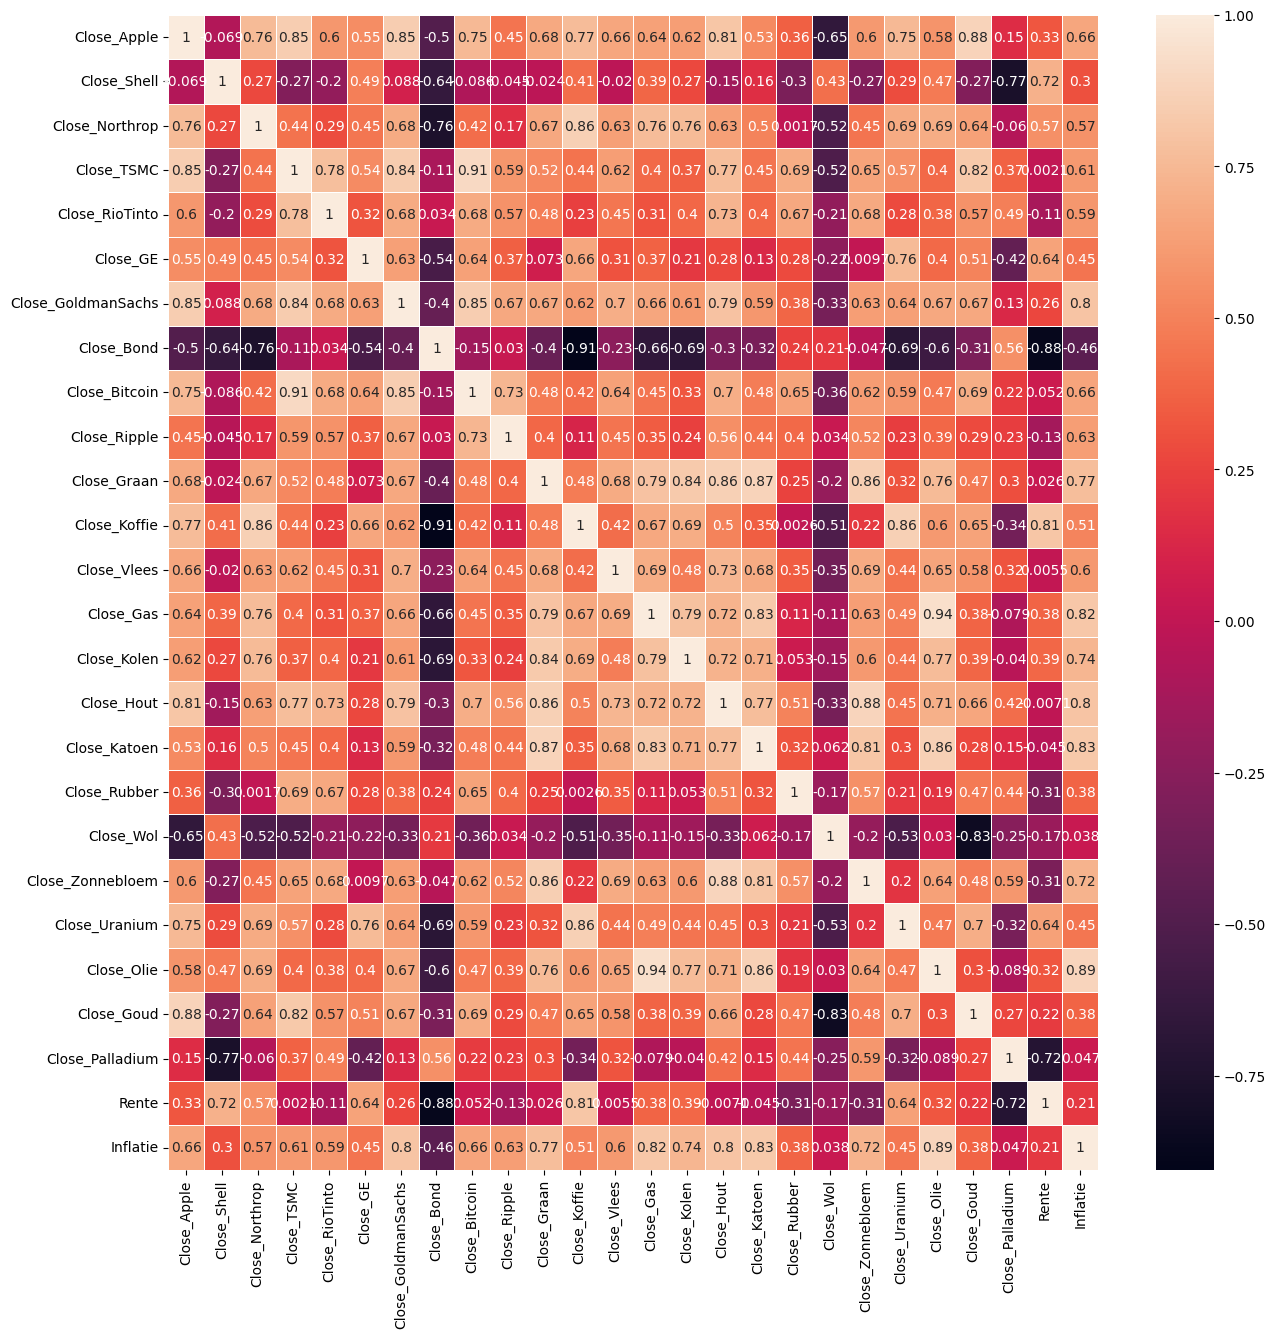

In [ ]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(apt_fill.corr(),annot=True, linewidths=.5, ax=ax)

Op basis van bovenstaande heatmap lijken er de volgende verbanden te zijn:<br>
- GRAAG HIER EEN DUIDELIJKE TOELICHTING OP DE UITKOMSTEN!!!!

Of we maken de heatmap op basis van de dagrendementen:

<Axes: >

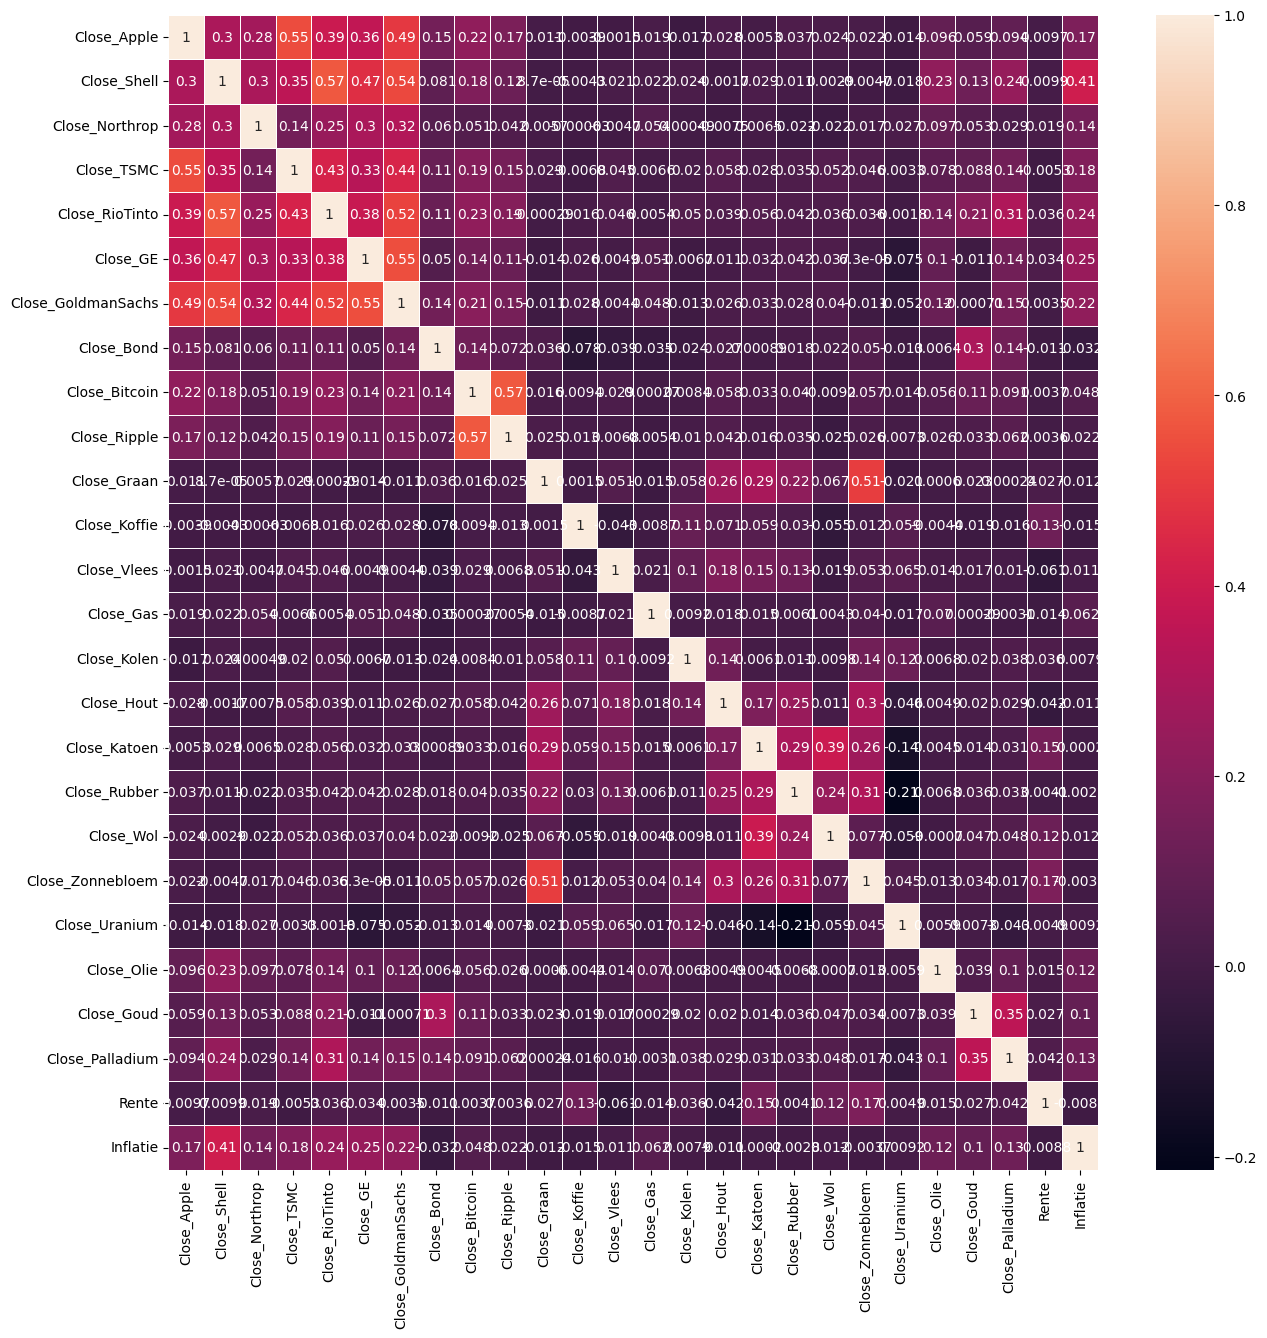

In [ ]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(return_portfolio_final.corr(), annot=True, linewidths=.5, ax=ax)
#sns.heatmap(return_portfolio_final.corr())

Op basis van bovenstaande heatmap lijken er de volgende verbanden te zijn tussen de dagrendementen:<br>
- alle aandelen zijn onderling gecorreleerd (behalve Northrop?)<br>
- bitcoin en ripple<br>
- goud en palladium<br>
- inflatie en shell?<br>
- goud en obligatie?<br>
- palladium en Rio Tinto





# Vuistregels voor wel/geen correlatie
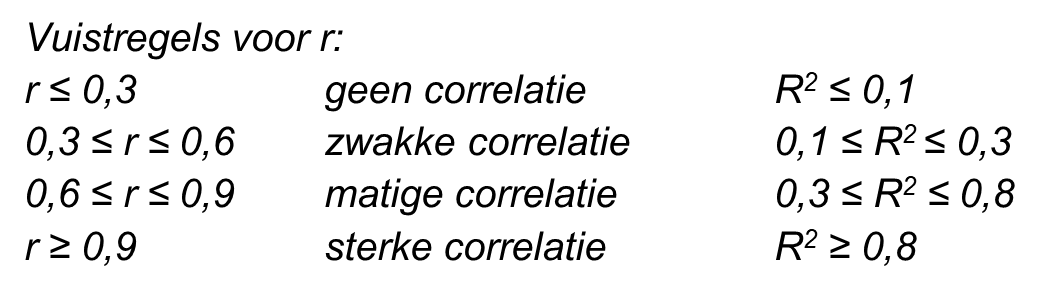

# Enkelvoudige regressie op basis van dagrendementen
Eens kijken of de regressie de resultaten van de correlatiematrix bevestigt:

In [ ]:
X = return_portfolio_final[["Inflatie"]]
y = return_portfolio_final[["Close_Shell"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Shell   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     430.7
Date:                Mon, 02 Dec 2024   Prob (F-statistic):           1.86e-87
Time:                        10:16:03   Log-Likelihood:                 5837.4
No. Observations:                2186   AIC:                        -1.167e+04
Df Residuals:                    2184   BIC:                        -1.166e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9.445e-05      0.000      0.263      0.7

Er is inderdaad een zwak positief verband tussen de verandering van de inflatie (op dagbasis) en het dagrendement van Shell.<br>
En het voorspelmodel: verandering dagrendement Shell = 0,00009445 + 0,3673 x verandering inflatie

NB: zie voor uitleg OLS Regression Results de Colab van werkplaats blok 1 les 7 regressie-analyse.

Andere manier om de de regressie te maken:

In [ ]:
X = return_portfolio_final[["Inflatie"]]
y = return_portfolio_final[["Close_Shell"]]

regressie = LinearRegression()

regressie.fit(X, y)
print("De R-kwadraat is", regressie.score(X, y))

De R-kwadraat is 0.1647083725886408


In [ ]:
return_portfolio_final["voorspelde_waarde"] = regressie.predict(X)

return_portfolio_final

<ipython-input-29-2304dbfa0768>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return_portfolio_final["voorspelde_waarde"] = regressie.predict(X)


,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium,Rente,Inflatie,voorspelde_waarde
2018-05-08,0.004807,0.004302,0.038281,0.018986,-0.001262,0.014215,-0.000843,-0.001266,-0.014743,-0.022424,...,0.000000,0.000000,0.000000,0.000000,-0.023611,-0.000152,0.001348,0.0,-0.004608,-0.001598
2018-05-09,0.007041,0.023990,-0.005102,0.004339,0.020754,0.024527,0.019958,-0.001462,0.009785,-0.014653,...,0.000000,0.000000,0.000000,0.000000,0.030119,-0.000533,0.007457,0.0,0.009259,0.003495
2018-05-10,0.014304,-0.009483,-0.003602,0.010673,0.013967,0.004788,0.007074,0.001171,-0.030159,-0.054618,...,0.000000,0.000000,0.000000,0.000000,0.003093,0.007245,0.023951,0.0,-0.004587,-0.001590
2018-05-11,-0.007630,0.013515,-0.003401,0.003520,0.000697,-0.006127,-0.002136,0.001268,-0.066614,-0.096657,...,0.000000,0.000000,0.000000,0.000000,-0.009249,-0.001363,-0.008734,0.0,-0.009217,-0.003291
2018-05-12,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.007510,0.017209,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.005273,-0.015846,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000094
2024-04-28,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.004824,-0.014288,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000094
2024-04-29,0.024808,-0.002047,0.012010,0.001446,0.011284,0.013181,0.007578,0.003927,0.011533,0.009904,...,0.000000,0.000000,0.000000,0.000000,-0.014550,0.004540,0.020159,0.0,-0.008230,-0.002929
2024-04-30,-0.018271,-0.019967,-0.002447,-0.008375,-0.017099,-0.016232,-0.009517,-0.003241,-0.050191,-0.029814,...,0.000000,0.000000,0.000000,0.000000,-0.008471,-0.023024,-0.025392,0.0,0.000000,0.000094


Plaatje met in het blauw het werkelijke dagrendement van Shell, in het groen het voorspelde dagrendement:

<Axes: >

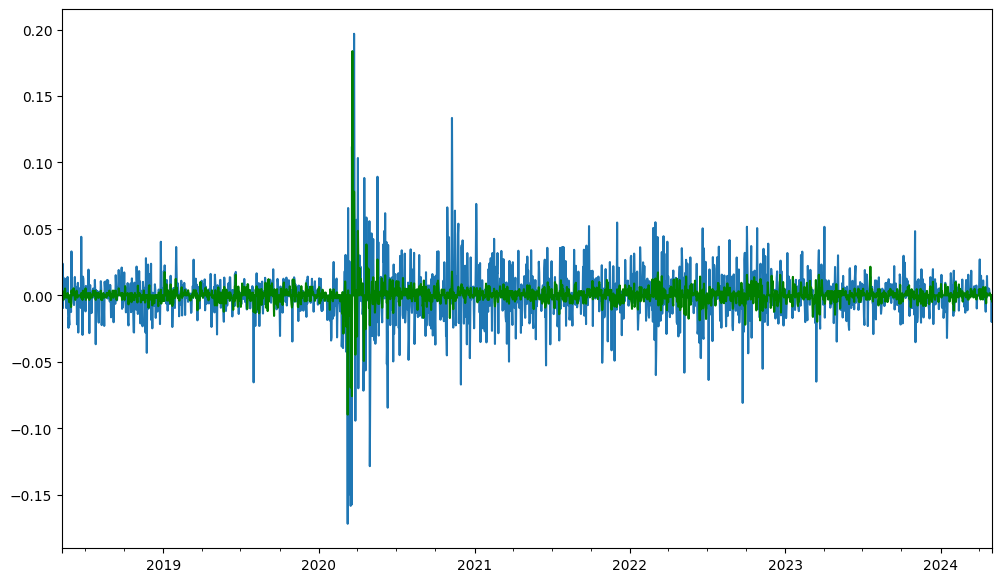

In [ ]:
return_portfolio_final['Close_Shell'].plot(figsize = (12,7), label='Price in USD')
return_portfolio_final['voorspelde_waarde'].plot(color="green", label='Regression')

Conclusie: dit is geen best voorspelmodel ..

# Meervoudige regressie op basis van dagrendementen
We gaan kijken of er een verband is tussen het dagrendement van Apple en de veranderingen in de inflatie, rente en de prijs van hout.<br>


Manier 1:

In [ ]:
X = return_portfolio_final[["Inflatie", "Rente", "Close_Hout"]]
y = return_portfolio_final[["Close_Apple"]]

regressie = LinearRegression()

regressie.fit(X, y)
print("De R-kwadraat is", regressie.score(X, y))

De R-kwadraat is 0.031183234450937736


In [ ]:
regressie.coef_

array([[0.14123095, 0.00361453, 0.08620293]])

In [ ]:
regressie.intercept_

array([0.00068131])

Manier 2:<br>
Wat is nu het model?

In [ ]:
X = return_portfolio_final[["Inflatie", "Rente", "Close_Hout"]]
y = return_portfolio_final[["Close_Apple"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Apple   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     23.41
Date:                Mon, 02 Dec 2024   Prob (F-statistic):           6.52e-15
Time:                        10:17:45   Log-Likelihood:                 5913.7
No. Observations:                2186   AIC:                        -1.182e+04
Df Residuals:                    2182   BIC:                        -1.180e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.965      0.0

Dus model is:<br>
verandering dagrendement Apple = 0,0007 + 0,1412 x verandering inflatie + 0,0034 x verandering rente + 0,0862 x prijsverandering hout

Maar: model is niet geldig, want p-waarde rente & hout zijn > 0,05. Bovendien is de R-kwadraat zo laag (0,031) dat er geen verband is tussen dagrendement Apple en de gekozen macro-economische indicatoren en de grondstof hout.

# Enkelvoudige regressie op basis van dagkoersen
In plaats van dat we de regressie draaien op basis van dagelijkse koers**rendementen**, gaan we kijken of we op basis van **dagkoersen** verbanden kunnen vinden en voorspelmodellen kunnen maken.


Let Wel: theoretisch is dit, op basis van de [efficiente markttheorie](https://en.wikipedia.org/wiki/Efficient-market_hypothesis), onzin ..

We gaan kijken of we de koers van goud kunnen voorspellen op basis van de koers van de obligatie:

In [ ]:
X = apt_fill[["Close_Bond"]]
y = apt_fill[["Close_Goud"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:             Close_Goud   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     229.3
Date:                Mon, 02 Dec 2024   Prob (F-statistic):           2.46e-49
Time:                        10:20:57   Log-Likelihood:                -15230.
No. Observations:                2187   AIC:                         3.046e+04
Df Residuals:                    2185   BIC:                         3.047e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2728.8499     67.619     40.356      0.0

Nee dus ...

# Meervoudige regressie op basis van dagkoersen

Naast enkelvoudig kunnen we ook meervoudig gaan analyseren: we gaan kijken of we de koers van Apple kunnen voorspellen op basis van de inflatie, de rente en de prijs van hout:

In [ ]:
X = apt_fill[["Inflatie", "Rente", "Close_Hout"]]
y = apt_fill[["Close_Apple"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Apple   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     2513.
Date:                Mon, 02 Dec 2024   Prob (F-statistic):               0.00
Time:                        10:21:50   Log-Likelihood:                -10050.
No. Observations:                2187   AIC:                         2.011e+04
Df Residuals:                    2183   BIC:                         2.013e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -198.4031      3.792    -52.320      0.0

Het model is geldig (p-waarden kleiner dan 0,05) en de R-kwadraat is behoorlijk (maar verband = matig): 0,775.
<p>
De koers van Apple = -198,4 - 22,2 x inflatie% + 9,8 x rente% + 1,2 x prijs van hout.

Kunnen we ook de koers van de bitcoin voorspellen?

In [ ]:
X = apt_fill[["Inflatie", "Rente", "Close_Hout"]]
y = apt_fill[["Close_Bitcoin"]]

regressie = LinearRegression()

regressie.fit(X, y)
print("De R-kwadraat is", regressie.score(X, y))
print("De regressiecoefficienten zijn", regressie.coef_)
print("De constante is", regressie.intercept_)

De R-kwadraat is 0.5141136230143288
De regressiecoefficienten zijn [[ 1.18645796e+04 -7.07420486e+00  2.13887055e+02]]
De constante is [-61295.1622021]


Of met het fijne overzicht erbij:

In [ ]:
X = apt_fill[["Inflatie", "Rente", "Close_Hout"]]
y = apt_fill[["Close_Bitcoin"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:          Close_Bitcoin   R-squared:                       0.514
Model:                            OLS   Adj. R-squared:                  0.513
Method:                 Least Squares   F-statistic:                     769.9
Date:                Mon, 02 Dec 2024   Prob (F-statistic):               0.00
Time:                        10:25:18   Log-Likelihood:                -23716.
No. Observations:                2187   AIC:                         4.744e+04
Df Residuals:                    2183   BIC:                         4.746e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -6.13e+04   1961.497    -31.249      0.0

Koers van de bitcoin = -61.300 + 11.860 x inflatie% - 7.0 x rente% + 213,8 x prijs van hout

Laatste variant: kunnen we de rente voorspellen op basis van de koersen van Apple en de bitcoin?

In [ ]:
X = apt_fill[["Close_Apple", "Close_Bitcoin"]]
y = apt_fill[["Rente"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Rente   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.197
Method:                 Least Squares   F-statistic:                     269.2
Date:                Mon, 02 Dec 2024   Prob (F-statistic):          3.20e-105
Time:                        10:29:38   Log-Likelihood:                -4274.8
No. Observations:                2187   AIC:                             8556.
Df Residuals:                    2184   BIC:                             8573.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.2715      0.095      2.848

De rentestand = 0,2715 + 0,0253 x koers_Apple - 0,00004855 x koers_bitcoin.
<p>
NB: de R-kwadraat is hier laag, ook hier: geen geweldig voorspelmodel.